# 12 - Callaway-Sant'Anna ATT with R `did`, by control group, with exact spatial-HAC inference

Main estimates for the paper and the FLARE slides, on the **STATUS_YR-based treatment dating** (definition C, set in notebook 02 and compared in notebook 11).

**Estimator.** ATT(g,t) and their aggregates come from **R's `did` package** (Callaway & Sant'Anna's reference implementation; doubly robust estimates via Sant'Anna & Zhao's `DRDID`), run through `utils/r_did_bridge.py`. The Python `csdid` port used in notebook 08 is not used: on notebook 08's own data it disagreed with R `did` (and with the textbook 2x2 formula) in 244 of 263 post-treatment cells when all cohorts were estimated together.

**Inference.** R exports the influence function of the overall ATT and of each event-time ATT (including the estimation of the cohort weights and, for DR, of the nuisance models). The **spatial-HAC (Conley) SE** applies the 35 km Bartlett kernel to these influence functions exactly, for every pair of cells, with an FFT convolution on a 500 m lattice (`utils/fast_did_utils.ConleyLattice`; matches the exact pair sum to 0.005%). With a diagonal kernel it reproduces R's analytic SE, which is checked for every run. Notebook 08 capped its HAC at 50 million pairs (dropping most 35 km pairs) and combined per-(g,t) SEs as if independent.

**Control groups.** The main specification uses never-treated cells more than 35 km from any protected cell. Robustness: all never-treated cells; non-overlapping distance bands 2-10, 10-20 and 20-35 km; not-yet-treated cells (R `did`'s `notyettreated`, without never-treated cells); and a **buffered not-yet-treated** group (future protected cells more than 35 km from every cell already protected in the relevant year).

**Specifications** (as notebook 08): `baseline` (no covariates), `anticipation1`, `dr_geography` (7 covariates: geography, baseline forest, nightlights, coca; doubly robust), `dr_geography_anticipation1`.

**Covariate windows.** Nightlights are the harmonised NPP-VIIRS-like series of Chen et al. (2021, ESSD; notebook 04c), one consistent series for 2000-2025, instead of DMSP (which ends in 2013, so every cohort from 2015 had the same nightlights window as every other) or VIIRS (which starts in 2012-2013 and had to be imputed). Nightlights and coca change over time, so they enter as **running pre-means** (`utils/covariate_windows.py`): for every cell and year *t*, the mean over the years up to *t*. R `did` takes covariates from each comparison's base period (*g*-1, or *g*-2 with anticipation), so a cohort and its controls are always measured over the same years. Notebook 04's frozen covariates measured treated cells over the years before their own treatment but never-treated cells over a fixed window ending in 2013, so for cohorts before 2014 the two groups' nightlights and coca covered different years. At *g*-1 the running mean equals notebook 04's value for treated cells exactly (checked below). Geography and baseline forest are time-invariant. A TWFE benchmark (`pyfixest`) is estimated for newly added PAs and for all PA cells against the same control groups, with the same spatial HAC.

Two runs are not done in R, and are labelled in every table:
* **All never-treated, no-covariate specs**: the R job would need more memory than this machine has. They use the Python estimator in `utils/fast_did_utils.py`, which reproduces R `did` exactly for no-covariate specs (checked in this notebook). The DR specs of this group run in R on a fixed random third of the never-treated controls.
* **Buffered not-yet-treated**: R `did` cannot restrict not-yet-treated controls by a year-specific condition, so this group uses the Python estimator (no-covariate specs identical to R; DR specs use the in-house plug-in DR of notebook 08, which regularises and trims the propensity score).

In [1]:
from pathlib import Path
import math
import shutil
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyfixest as pf
from scipy.spatial import cKDTree

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'notebooks').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from utils.fast_did_utils import outcome_matrix, cohort_att_gt, GTAccumulator, ConleyLattice
from utils.r_did_bridge import find_rscript, write_r_inputs, run_r, read_run, remove_run_files
from utils.covariate_windows import build_dr_covariates

INTERMEDIATE_DIR = PROJECT_ROOT / 'data' / 'intermediate'
TABLE_DIR = PROJECT_ROOT / 'outputs' / 'tables'
FIG_DIR = PROJECT_ROOT / 'outputs' / 'figures'
warnings.filterwarnings('ignore', category=FutureWarning)
print('Project root:', PROJECT_ROOT, '| Rscript:', find_rscript())

Project root: C:\Users\cpedr\OneDrive - Hertie School\PhD\Paper 2\paper2 | Rscript: C:\Program Files\R\R-4.5.3\bin\Rscript.exe


## Configuration

In [2]:
RUN_TAG = '1km'
START_YEAR = 2001
CELL_COL, YEAR_COL, OUTCOME_COL = 'cell_id', 'year', 'loss_m2'
PANEL_PATH = INTERMEDIATE_DIR / f'panel_treatment_{RUN_TAG}.parquet'
COVARIATE_PATH = INTERMEDIATE_DIR / f'panel_core_covariates_{RUN_TAG}.parquet'
CENTROID_PATH = INTERMEDIATE_DIR / 'spatial_structure' / f'03_grid_centroids_{RUN_TAG}.parquet'
DATING_PATH = INTERMEDIATE_DIR / f'protected_area_dating_{RUN_TAG}.parquet'
GEE_COVARIATE_DIR = PROJECT_ROOT / 'data' / 'raw' / 'gee_covariates_core_1km'      # notebook 04's annual DMSP exports (checks)
CHEN_NTL_PATH = INTERMEDIATE_DIR / f'chen_ntl_{RUN_TAG}.parquet'                   # notebook 04c: Chen et al. nightlights, 2000-2025
COCA_PANEL_PATH = INTERMEDIATE_DIR / f'panel_coca_{RUN_TAG}.parquet'               # notebook 04's annual coca panel
R_WORK_DIR = INTERMEDIATE_DIR / '12_r_did_work'          # temporary inputs/outputs for R (deleted at the end)
R_LOG = TABLE_DIR / f'12_r_did_log_{RUN_TAG}.txt'

MAIN_GROUP = 'buffer_35'
# engine: 'R' (R did) or 'python' (utils.fast_did_utils). Order = run order (main specification first).
CONTROL_GROUPS = [
    {'key': 'buffer_35', 'label': '> 35 km (main)', 'type': 'never', 'band': (35, None)},
    {'key': 'band_2_10', 'label': '2-10 km', 'type': 'never', 'band': (2, 10)},
    {'key': 'band_10_20', 'label': '10-20 km', 'type': 'never', 'band': (10, 20)},
    {'key': 'band_20_35', 'label': '20-35 km', 'type': 'never', 'band': (20, 35)},
    {'key': 'all_never', 'label': 'All never-treated', 'type': 'never', 'band': (None, None)},
    {'key': 'not_yet', 'label': 'Not-yet-treated', 'type': 'notyet', 'band': (None, None)},
    {'key': 'not_yet_buffer35', 'label': 'Not-yet-treated > 35 km', 'type': 'notyet_buffer', 'band': (35, None)},
]
ALL_NEVER_DR_CONTROL_FRACTION, R_SEED = 1 / 3, 20261015

GEOGRAPHY_COVARIATES = ['elevation_m_mean', 'slope_deg_mean', 'ruggedness_m_mean', 'base_m2']
NIGHTLIGHTS_COVARIATE = 'chen_ntl_pre_mean'
COCA_COVARIATE, COCA_MISSING_FLAG = 'coca_pre_mean_ha', 'coca_data_missing'
# Nightlights: Chen et al. (2021) harmonised NPP-VIIRS-like series, 2000-2025 (notebook 04c, Earth Engine aggregation design).
# DMSP ends in 2013 and VIIRS starts in 2012-2013 (it had to be imputed for earlier cohorts, and the DR estimate was sensitive to
# that); notebook 13 re-estimates the DR with DMSP for comparison.
# Nightlights and coca are time-varying running pre-means (same window for a cohort and its controls); the rest is time-invariant.
TIME_VARYING_COVARIATES = [NIGHTLIGHTS_COVARIATE, COCA_COVARIATE]
STATIC_COVARIATES = GEOGRAPHY_COVARIATES + [COCA_MISSING_FLAG]
DR_COVARIATES = GEOGRAPHY_COVARIATES + [NIGHTLIGHTS_COVARIATE, COCA_COVARIATE, COCA_MISSING_FLAG]
SPECS = [
    {'spec': 'baseline', 'covariates': False, 'anticipation': 0},
    {'spec': 'anticipation1', 'covariates': False, 'anticipation': 1},
    {'spec': 'dr_geography', 'covariates': True, 'anticipation': 0},
    {'spec': 'dr_geography_anticipation1', 'covariates': True, 'anticipation': 1},
]
PSCORE_TRIM, PS_CV, PS_MAX_WEIGHT = 0.02, 5, 100.0      # in-house DR (buffered not-yet group only), as notebook 08
HAC_CUTOFF_KM, HAC_KERNEL, HAC_LATTICE_M = 35.0, 'bartlett', 500.0
EVENT_WINDOW = (-8, 5)

## Data

Treatment year from the re-dated panel (notebook 02). Cohorts 2002-2025 are the treated groups; cells protected before 2001 are always treated within the panel (used only in the TWFE "all PA cells" models); cells first protected in 2001 have no pre-period and are left out, as in notebook 08. Covariates: geography and baseline forest (time-invariant); nightlights (Chen et al. 2000-2025, notebook 04c) and coca (2001-2023, notebook 04's source) as running pre-means; coca is 0 with a missing-data flag outside the monitored SIMCI extent. VIIRS is no longer used: it starts in 2012-2013, so for cohorts before 2013 it had to be imputed from DMSP and geography, and the DR estimate was sensitive to that imputation (notebook 13).

In [3]:
t0 = time.time()
panel = pd.read_parquet(PANEL_PATH, columns=[CELL_COL, YEAR_COL, OUTCOME_COL, 'first_treat_year'])
panel[CELL_COL] = panel[CELL_COL].astype(str)
panel = panel[panel[YEAR_COL] >= START_YEAR]
cell_ids, years, Y = outcome_matrix(panel, CELL_COL, YEAR_COL, OUTCOME_COL)
first_year = panel.drop_duplicates(CELL_COL).set_index(CELL_COL)['first_treat_year'].reindex(cell_ids)
del panel
g_raw = first_year.fillna(0).astype(int).to_numpy()
never = g_raw == 0
in_window = g_raw > START_YEAR
pre_panel = (g_raw > 0) & (g_raw < START_YEAR)
g_cell = np.where(in_window, g_raw, 0)
n_cells = len(cell_ids)
uid = np.arange(1, n_cells + 1, dtype=np.int64)        # R unit id = position + 1
assert not np.isnan(Y).any(), 'outcome has missing values'
print(f'{n_cells:,} cells x {len(years)} years ({years.min()}-{years.max()})  [{time.time() - t0:.0f}s]')
print(f'never treated {never.sum():,} | treated 2002-2025 {in_window.sum():,} | protected before 2001 {pre_panel.sum():,} | first protected 2001 {(g_raw == START_YEAR).sum():,}')

if DATING_PATH.exists():
    dating = pd.read_parquet(DATING_PATH, columns=[CELL_COL, 'year_statusyr_expansions'])
    dating[CELL_COL] = dating[CELL_COL].astype(str)
    chk = dating.set_index(CELL_COL)['year_statusyr_expansions'].reindex(cell_ids[~never]).to_numpy()
    print('Panel uses the STATUS_YR-based dating (definition C):', bool((chk == g_raw[~never]).all()))

cent = pd.read_parquet(CENTROID_PATH, columns=[CELL_COL, 'centroid_x_m', 'centroid_y_m'])
cent[CELL_COL] = cent[CELL_COL].astype(str)
xy = cent.set_index(CELL_COL).reindex(cell_ids)[['centroid_x_m', 'centroid_y_m']].to_numpy(dtype=float)
assert not np.isnan(xy).any()

analysis = never | in_window
dr_cov = build_dr_covariates(cell_ids, years, g_raw, covariate_path=COVARIATE_PATH, gee_dir=GEE_COVARIATE_DIR, coca_panel_path=COCA_PANEL_PATH,
                             geography=GEOGRAPHY_COVARIATES, nightlights=NIGHTLIGHTS_COVARIATE, coca=COCA_COVARIATE, coca_flag=COCA_MISSING_FLAG,
                             chen_path=CHEN_NTL_PATH)
assert dr_cov['names'] == DR_COVARIATES
covariates = dr_cov['static']                  # time-invariant part (R cells.csv)
covariates_by_year = dr_cov['by_year']         # nightlights and coca running pre-means (R long.csv)
x_at = dr_cov['x_at']                          # covariates at one base year (Python estimator)
_, xc_last = x_at(years[-1])
print(f'Cells with complete DR covariates: {int((xc_last & analysis).sum()):,} of {int(analysis.sum()):,} analysis cells')
nl = covariates_by_year[NIGHTLIGHTS_COVARIATE]
for g in (2005, 2010, 2018, 2022):
    j = g - 1 - years[0]
    print(f'  cohort {g}: mean nightlights (Chen) at g-1: cohort {np.nanmean(nl[g_raw == g, j]):.3f} | never-treated {np.nanmean(nl[never, j]):.3f}')

1,160,018 cells x 25 years (2001-2025)  [22s]
never treated 933,675 | treated 2002-2025 103,335 | protected before 2001 122,923 | first protected 2001 85
Panel uses the STATUS_YR-based dating (definition C): True


dmsp_stable_lights_pre_mean: running mean at g-1 = notebook 04 value for 100.0% of treated cells (max diff 1.4e-14); never-treated at 2013: 100.0%
coca_pre_mean_ha: running mean at g-1 = notebook 04 value for 100.0% of treated cells (max diff 1.8e-15); never-treated at 2013: 100.0%


chen_ntl_pre_mean: Chen et al. running pre-mean from 2000; cells without data 0


Cells with complete DR covariates: 1,037,010 of 1,037,010 analysis cells
  cohort 2005: mean nightlights (Chen) at g-1: cohort 0.066 | never-treated 0.090
  cohort 2010: mean nightlights (Chen) at g-1: cohort 0.088 | never-treated 0.091
  cohort 2018: mean nightlights (Chen) at g-1: cohort 0.075 | never-treated 0.115
  cohort 2022: mean nightlights (Chen) at g-1: cohort 0.078 | never-treated 0.125


## Control groups

Distance from each never-treated cell to the nearest protected cell of any age (treatment is absorbing and every protected cell is protected by 2025, so this is the minimum over the panel: the measure behind the 35 km main buffer). Bands are non-overlapping: (2, 10], (10, 20], (20, 35] and (35, inf) km. For the buffered not-yet-treated group, a future protected cell is an admissible control at (g, t) only if it is more than 35 km from every cell protected by year max(t, base year).

In [4]:
dist_km = cKDTree(xy[~never]).query(xy, k=1)[0] / 1000.0
control_masks = {}
for cg in CONTROL_GROUPS:
    lo, hi = cg['band']
    m = never.copy() if cg['type'] == 'never' else np.zeros(n_cells, dtype=bool)
    if cg['type'] == 'never':
        if lo is not None:
            m &= dist_km > lo
        if hi is not None:
            m &= dist_km <= hi
    control_masks[cg['key']] = m

# year-specific eligibility of future protected cells (buffered not-yet-treated group)
notyet_ok = np.zeros((n_cells, len(years)), dtype=bool)
tw = np.flatnonzero(in_window)
for j, yr in enumerate(years):
    prot = (g_raw > 0) & (g_raw <= yr)
    if prot.any():
        d_y = cKDTree(xy[prot]).query(xy[tw], k=1)[0] / 1000.0
        notyet_ok[tw, j] = d_y > 35.0
    else:
        notyet_ok[tw, j] = True

loss_mean = Y.mean(axis=1)
pre_obs = np.zeros_like(Y, dtype=bool)
for j, yr in enumerate(years):
    pre_obs[:, j] = in_window & (yr < g_cell)
CONTROL_MEAN = {}
rows = []
for cg in CONTROL_GROUPS:
    if cg['type'] == 'never':
        n_ctrl, cm = int(control_masks[cg['key']].sum()), float(loss_mean[control_masks[cg['key']]].mean())
    else:   # not-yet: control mean = treated cells' mean annual loss before their own treatment
        n_ctrl, cm = int(in_window.sum()), float(Y[pre_obs].mean())
    CONTROL_MEAN[cg['key']] = cm
    rows.append({'control_group': cg['label'], 'control_cells': n_ctrl, 'control_mean_annual_loss_m2': round(cm, 1)})
display(pd.DataFrame(rows))
print('Share of future protected cells eligible (> 35 km from protected cells) by year:',
      {int(y): round(float(notyet_ok[tw, j].mean()), 2) for j, y in enumerate(years) if y in (2005, 2010, 2015, 2020, 2024)})
cohort_sizes = pd.Series(g_cell[in_window]).value_counts().sort_index()
print('Cohorts:', cohort_sizes.to_dict())

,control_group,control_cells,control_mean_annual_loss_m2
0,> 35 km (main),264952,1306.5
1,2-10 km,250387,1766.4
2,10-20 km,200266,1887.8
3,20-35 km,166622,1930.6
4,All never-treated,933675,1682.1
5,Not-yet-treated,103335,1016.3
6,Not-yet-treated > 35 km,103335,1016.3


Share of future protected cells eligible (> 35 km from protected cells) by year: {2005: 0.45, 2010: 0.18, 2015: 0.11, 2020: 0.01, 2024: 0.0}
Cohorts: {2002: 11294, 2003: 96, 2004: 41, 2005: 1135, 2006: 780, 2007: 4207, 2008: 2672, 2009: 14456, 2010: 1167, 2011: 12197, 2012: 920, 2013: 1797, 2014: 1648, 2015: 3892, 2016: 1655, 2017: 4331, 2018: 24337, 2019: 5214, 2020: 1779, 2021: 2287, 2022: 761, 2023: 1348, 2024: 4347, 2025: 974}


## Estimation

For each control group, R `did` (or the Python estimator where noted) estimates the four specifications. Each run's overall ATT (R's `simple` aggregation: cohort-size-weighted mean of the post-treatment ATT(g,t), t >= g) and event-time ATTs (`dynamic`, e = -8..5) get:

* **SE (HAC)**: exact Conley spatial HAC on the run's influence function (35 km Bartlett);
* **SE (analytic)**: R's own SE (independent cells); for Python runs, the same formula on its influence function.

Results are appended after every control group, so a later failure does not lose earlier results.

In [5]:
lattice = ConleyLattice(xy[:, 0], xy[:, 1], cutoff_km=HAC_CUTOFF_KM, res_m=HAC_LATTICE_M, kernel=HAC_KERNEL)
print(f'HAC lattice {lattice.shape}, cells sharing a node: {lattice.n_collisions}')

def normal_p(z):
    return math.erfc(abs(z) / math.sqrt(2.0)) if np.isfinite(z) else np.nan

def stars(p):
    return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else '.' if p < 0.1 else ''

R_WORK_DIR.mkdir(parents=True, exist_ok=True)
r_flags = {cg['key']: control_masks[cg['key']] for cg in CONTROL_GROUPS if cg['type'] == 'never'}
keep_for_r = in_window | np.logical_or.reduce(list(r_flags.values()))
long_path, cells_path = write_r_inputs(R_WORK_DIR, uid=uid, years=years, Y=Y, g_did=g_cell, keep=keep_for_r,
                                       control_flags=r_flags, covariates=covariates, covariates_by_year=covariates_by_year)
print('R inputs written:', long_path.name, cells_path.name)

overall_rows, event_rows, gt_frames, warn_rows = [], [], [], []

def record(cg, spec, engine, att, se_an, psi_overall, events, gt, note=''):
    se_hac = lattice.se(psi_overall)
    z = att / se_hac
    overall_rows.append({'control_group': cg['key'], 'control_label': cg['label'], 'spec': spec['spec'], 'engine': engine, 'note': note,
                         'att': att, 'se_hac': se_hac, 'se_analytic': se_an, 'hac_to_analytic': se_hac / se_an,
                         'ci_low': att - 1.96 * se_hac, 'ci_high': att + 1.96 * se_hac, 'p': normal_p(z), 'sig': stars(normal_p(z)),
                         'pct_of_control_mean': 100 * att / CONTROL_MEAN[cg['key']]})
    for e, (att_e, se_e_an, psi_e) in events.items():
        event_rows.append({'control_group': cg['key'], 'spec': spec['spec'], 'engine': engine, 'event_time': int(e),
                           'att': att_e, 'se_hac': lattice.se(psi_e), 'se_analytic': se_e_an})
    gt = gt.copy(); gt.insert(0, 'engine', engine); gt.insert(0, 'spec', spec['spec']); gt.insert(0, 'control_group', cg['key'])
    gt_frames.append(gt)
    print(f"  {cg['label']:<24} {spec['spec']:<27} [{engine}{(' ' + note) if note else ''}] ATT {att:>8.1f}  SE(HAC) {se_hac:>6.1f}  SE(analytic) {se_an:>6.1f} {stars(normal_p(z))}")

def run_python(cg, spec, control_type, ctrl_mask, notyet=None):
    acc = GTAccumulator(cohort_sizes.to_dict(), n_cells, anticipation=0, event_window=EVENT_WINDOW)   # post = t >= g, as R's simple
    cache = {}
    for g in sorted(int(c) for c in cohort_sizes.index):
        base_year = g - 1 - spec['anticipation']
        Xg, xcg = x_at(base_year) if (spec['covariates'] and base_year in years) else (None, None)   # covariates at the cohort's base year
        res, _ = cohort_att_gt(Y, years, g_cell, ctrl_mask, g, anticipation=spec['anticipation'], control_type=control_type,
                               x=Xg, x_complete=xcg, ps_cache=cache, ps_key=(cg['key'], spec['anticipation']),
                               ps_cv=PS_CV, ps_trim=PSCORE_TRIM, ps_max_weight=PS_MAX_WEIGHT, notyet_ok=notyet)
        acc.add(res)
        del res
    gt, overall, events = acc.result()
    ev = {e: (v['att'], float(np.sqrt(np.sum(v['psi'] ** 2))), v['psi']) for e, v in events.items()}
    return overall['att'], float(np.sqrt(np.sum(overall['psi'] ** 2))), overall['psi'], ev, gt[['group', 'time', 'att']]

def save_progress():
    pd.DataFrame(overall_rows).to_csv(TABLE_DIR / f'12_cs_overall_att_by_control_group_{RUN_TAG}.csv', index=False)
    pd.DataFrame(event_rows).to_csv(TABLE_DIR / f'12_cs_event_time_att_by_control_group_{RUN_TAG}.csv', index=False)
    pd.concat(gt_frames, ignore_index=True).to_csv(TABLE_DIR / f'12_cs_group_time_att_by_control_group_{RUN_TAG}.csv', index=False)
    pd.DataFrame(warn_rows).to_csv(TABLE_DIR / f'12_r_did_warnings_{RUN_TAG}.csv', index=False)

for cg in CONTROL_GROUPS:
    t1 = time.time()
    print(f"\n=== {cg['label']} ===")
    if cg['type'] == 'notyet_buffer':
        for spec in SPECS:
            att, se_an, psi, ev, gt = run_python(cg, spec, 'notyet', control_masks[cg['key']], notyet=notyet_ok)
            record(cg, spec, 'python', att, se_an, psi, ev, gt, note='in-house DR' if spec['covariates'] else '')
        save_progress()
        continue
    r_specs, py_specs = [], []
    for spec in SPECS:
        if cg['key'] == 'all_never' and not spec['covariates']:
            py_specs.append(spec)
        else:
            r_specs.append(spec)
    for spec in py_specs:
        att, se_an, psi, ev, gt = run_python(cg, spec, 'never', control_masks[cg['key']])
        record(cg, spec, 'python', att, se_an, psi, ev, gt, note='identical to R for no-covariate specs')
    if r_specs:
        runs = pd.DataFrame([{
            'run_id': f"{cg['key']}__{s['spec']}",
            'control_flag': f"ctrl_{cg['key']}" if cg['type'] == 'never' else 'none',
            'control_group': 'nevertreated' if cg['type'] == 'never' else 'notyettreated',
            'est_method': 'dr' if s['covariates'] else 'reg', 'use_covariates': bool(s['covariates']), 'anticipation': s['anticipation'],
            'control_fraction': ALL_NEVER_DR_CONTROL_FRACTION if (cg['key'] == 'all_never' and s['covariates']) else 1.0,
            'seed': R_SEED, 'min_e': EVENT_WINDOW[0], 'max_e': EVENT_WINDOW[1],
        } for s in r_specs])
        run_r(runs, R_WORK_DIR, long_path, cells_path, R_WORK_DIR / 'out', R_LOG)
        for s, run in zip(r_specs, runs.itertuples()):
            r = read_run(R_WORK_DIR / 'out', run.run_id)
            pos = np.searchsorted(uid, r['ids'])
            assert (uid[pos] == r['ids']).all()
            simple = r['agg'].query("type == 'simple'").iloc[0]
            psi = np.zeros(n_cells); psi[pos] = r['if_simple'] / r['n']
            assert abs(np.sqrt(np.sum(psi ** 2)) - simple['se']) < 1e-6 * max(1.0, simple['se']), 'HAC scaling check failed'
            dyn = r['agg'].query("type == 'dynamic'").set_index('e')
            ev = {}
            for k, e in enumerate(r['event_times']):
                pe = np.zeros(n_cells); pe[pos] = r['if_dynamic'][:, k] / r['n']
                ev[int(e)] = (float(dyn.loc[e, 'att']), float(dyn.loc[e, 'se']), pe)
            note = f"controls subsampled to {run.control_fraction:.0%}" if run.control_fraction < 1 else ''
            record(cg, s, 'R did', float(simple['att']), float(simple['se']), psi, ev, r['gt'][['group', 'time', 'att', 'se']], note=note)
            warn_rows += [{'control_group': cg['key'], 'spec': s['spec'], 'warning': w} for w in r['warnings'] if w != 'none']
            remove_run_files(R_WORK_DIR / 'out', run.run_id)
    save_progress()
    print(f"  [{cg['label']} done in {time.time() - t1:.0f}s]")

cs_overall = pd.DataFrame(overall_rows)
cs_events = pd.DataFrame(event_rows)
cs_gt = pd.concat(gt_frames, ignore_index=True)
r_warnings = pd.DataFrame(warn_rows)

HAC lattice (4464, 2891), cells sharing a node: 0


R inputs written: long.csv cells.csv

=== > 35 km (main) ===


  > 35 km (main)           baseline                    [R did] ATT   -103.6  SE(HAC)  124.2  SE(analytic)   22.3 


  > 35 km (main)           anticipation1               [R did] ATT   -337.0  SE(HAC)  180.1  SE(analytic)   29.6 .


  > 35 km (main)           dr_geography                [R did] ATT   -125.2  SE(HAC)  270.5  SE(analytic)   63.7 


...

  Not-yet-treated          dr_geography_anticipation1  [R did] ATT    117.7  SE(HAC)  186.4  SE(analytic)   76.3 
  [Not-yet-treated done in 441s]

=== Not-yet-treated > 35 km ===


  Not-yet-treated > 35 km  baseline                    [python] ATT    673.2  SE(HAC)  285.8  SE(analytic)  177.1 *


  Not-yet-treated > 35 km  anticipation1               [python] ATT    206.2  SE(HAC)  329.9  SE(analytic)  198.7 


  Not-yet-treated > 35 km  dr_geography                [python in-house DR] ATT -12752.9  SE(HAC) 6954.7  SE(analytic) 1161.6 .


  Not-yet-treated > 35 km  dr_geography_anticipation1  [python in-house DR] ATT -14004.5  SE(HAC) 5970.9  SE(analytic) 1015.7 *


### Check: R `did` against the Python estimator

For the main specification's no-covariate runs, every post-treatment ATT(g,t) from R must equal the Python estimator's (the same 2x2 formula). This is what justifies using the Python estimator for the two groups R cannot run.

In [6]:
for spec in [s for s in SPECS if not s['covariates']]:
    r_gt = cs_gt[(cs_gt['control_group'] == MAIN_GROUP) & (cs_gt['spec'] == spec['spec'])]
    _, _, _, _, py_gt = run_python({'key': MAIN_GROUP}, spec, 'never', control_masks[MAIN_GROUP])
    m = r_gt.merge(py_gt, on=['group', 'time'], suffixes=('_r', '_py'))
    m = m[m['time'] >= m['group']]
    print(f"{spec['spec']}: {len(m)} post-treatment cells, max |R - Python| = {np.abs(m['att_r'] - m['att_py']).max():.2e}")

if len(r_warnings):
    print('\nR warnings (count by control group and spec):')
    display(r_warnings.assign(warning=r_warnings['warning'].str.slice(0, 90)).value_counts(['control_group', 'spec', 'warning']).rename('n').reset_index())
else:
    print('No R warnings.')

baseline: 300 post-treatment cells, max |R - Python| = 2.55e-11


anticipation1: 276 post-treatment cells, max |R - Python| = 7.64e-11
No R warnings.


## TWFE benchmark: newly added PAs and all PA cells

$\text{loss}_{it} = \beta D_{it} + \alpha_i + \gamma_t + \varepsilon_{it}$ (`pyfixest`), against the same control groups. **New PAs**: cohorts 2002-2025. **All PA cells**: plus cells protected before 2001 (always treated). In the not-yet-treated column the sample has no never-treated cells, so $\beta$ comes from timing differences among protected cells only; the buffered not-yet group has a year-specific control set and is not estimated by TWFE. The spatial-HAC SE uses each cell's summed score $\sum_t \tilde D_{it}\hat\varepsilon_{it} / \sum \tilde D^2$ (two-way demeaned $D$ times the residual): any serial correlation within a cell plus the 35 km Bartlett spatial correlation. The cell-clustered SE is reported alongside.

In [7]:
twfe_rows = []
for cg in CONTROL_GROUPS:
    if cg['type'] == 'notyet_buffer':
        continue
    ctrl = control_masks[cg['key']]
    for label, treated_set in [('TWFE new PAs', in_window), ('TWFE all PA cells', in_window | pre_panel)]:
        t1 = time.time()
        sel = np.flatnonzero(treated_set | ctrl)
        gi = np.repeat(g_raw[sel], len(years))
        yy = np.tile(years, len(sel))
        df = pd.DataFrame({'cell': np.repeat(sel, len(years)).astype(np.int32), 'year': yy.astype(np.int32),
                           'y': Y[sel].ravel(), 'D': ((gi > 0) & (yy >= gi)).astype(np.int8)})
        fit = pf.feols('y ~ D | cell + year', data=df, vcov={'CRV1': 'cell'})
        b, se_cell = float(fit.coef()['D']), float(fit.se()['D'])
        Xd, u = np.asarray(fit._X).ravel(), np.asarray(fit._u_hat).ravel()
        assert len(Xd) == len(df)
        psi = np.bincount(df['cell'].to_numpy(), weights=Xd * u / np.sum(Xd * Xd), minlength=n_cells)
        se_hac = lattice.se(psi)
        z = b / se_hac
        twfe_rows.append({'control_group': cg['key'], 'control_label': cg['label'], 'spec': label, 'engine': 'pyfixest', 'note': '',
                          'att': b, 'se_hac': se_hac, 'se_analytic': se_cell, 'hac_to_analytic': se_hac / se_cell,
                          'ci_low': b - 1.96 * se_hac, 'ci_high': b + 1.96 * se_hac, 'p': normal_p(z), 'sig': stars(normal_p(z)),
                          'pct_of_control_mean': 100 * b / CONTROL_MEAN[cg['key']]})
        print(f"{cg['label']:<24} {label:<18} beta {b:>8.1f}  SE(HAC) {se_hac:>6.1f}  SE(cell) {se_cell:>6.1f} {twfe_rows[-1]['sig']:<3} N={len(df):,} [{time.time() - t1:.0f}s]")
        del df, fit, psi
twfe = pd.DataFrame(twfe_rows)
twfe.to_csv(TABLE_DIR / f'12_twfe_by_control_group_{RUN_TAG}.csv', index=False)

> 35 km (main)           TWFE new PAs       beta   -389.1  SE(HAC)  154.1  SE(cell)   18.8 *   N=9,207,175 [10s]


> 35 km (main)           TWFE all PA cells  beta   -388.5  SE(HAC)  134.5  SE(cell)   17.9 **  N=12,280,250 [7s]


2-10 km                  TWFE new PAs       beta   -137.3  SE(HAC)   97.5  SE(cell)   19.0     N=8,843,050 [6s]


2-10 km                  TWFE all PA cells  beta   -211.1  SE(HAC)   98.7  SE(cell)   18.0 *   N=11,916,125 [7s]


10-20 km                 TWFE new PAs       beta   -350.9  SE(HAC)  130.8  SE(cell)   20.1 **  N=7,590,025 [5s]


...

20-35 km                 TWFE all PA cells  beta   -423.4  SE(HAC)  127.0  SE(cell)   18.7 *** N=9,822,000 [6s]


All never-treated        TWFE new PAs       beta   -353.3  SE(HAC)  106.4  SE(cell)   17.2 *** N=25,925,250 [17s]


All never-treated        TWFE all PA cells  beta   -357.1  SE(HAC)  104.1  SE(cell)   17.1 *** N=28,998,325 [17s]


Not-yet-treated          TWFE new PAs       beta      5.8  SE(HAC)  126.0  SE(cell)   21.4     N=2,583,375 [2s]


Not-yet-treated          TWFE all PA cells  beta   -285.4  SE(HAC)  136.6  SE(cell)   19.1 *   N=5,656,450 [4s]


## Main results table (slide 6): > 35 km buffer

ATT on annual forest loss (m² per 1 km² cell-year). SE (HAC) = exact Conley spatial HAC, 35 km Bartlett, used for the stars (\*\*\* p<0.001, \*\* p<0.01, \* p<0.05, . p<0.1); SE (analytic) = R `did`'s SE assuming independent cells (cell-clustered SE for TWFE).

In [8]:
both = pd.concat([cs_overall.assign(estimator='Callaway-Sant\'Anna (R did)'), twfe.assign(estimator='TWFE (pyfixest)')], ignore_index=True)
both.to_csv(TABLE_DIR / f'12_results_long_{RUN_TAG}.csv', index=False)
order_rows = [s['spec'] for s in SPECS] + ['TWFE new PAs', 'TWFE all PA cells']
main = both[both['control_group'] == MAIN_GROUP].set_index('spec').reindex(order_rows)
main_table = main[['estimator', 'att', 'se_hac', 'se_analytic', 'sig', 'pct_of_control_mean', 'ci_low', 'ci_high', 'engine', 'note']].round(1)
display(main_table)
main_table.to_csv(TABLE_DIR / f'12_main_results_buffer35_{RUN_TAG}.csv')
print(f"Control mean annual loss (> 35 km): {CONTROL_MEAN[MAIN_GROUP]:,.1f} m² per cell-year")

,estimator,att,se_hac,se_analytic,sig,pct_of_control_mean,ci_low,ci_high,engine,note
spec,,,,,,,,,,
baseline,Callaway-Sant'Anna (R did),-103.6,124.2,22.3,,-7.9,-347.1,139.8,R did,
anticipation1,Callaway-Sant'Anna (R did),-337.0,180.1,29.6,.,-25.8,-690.0,16.0,R did,
dr_geography,Callaway-Sant'Anna (R did),-125.2,270.5,63.7,,-9.6,-655.5,405.0,R did,
dr_geography_anticipation1,Callaway-Sant'Anna (R did),-54.7,373.9,61.7,,-4.2,-787.6,678.2,R did,
TWFE new PAs,TWFE (pyfixest),-389.1,154.1,18.8,*,-29.8,-691.2,-87.0,pyfixest,
TWFE all PA cells,TWFE (pyfixest),-388.5,134.5,17.9,**,-29.7,-652.2,-124.9,pyfixest,


Control mean annual loss (> 35 km): 1,306.5 m² per cell-year


## Robustness: all control groups

In [9]:
both['cell'] = both['att'].map('{:,.1f}'.format) + both['sig'] + ' (' + both['se_hac'].map('{:,.1f}'.format) + ')'
order_cols = [c['label'] for c in CONTROL_GROUPS]
grid = both.pivot(index='spec', columns='control_label', values='cell').reindex(index=order_rows, columns=order_cols)
display(grid)
grid.to_csv(TABLE_DIR / f'12_results_table_by_control_group_{RUN_TAG}.csv')
pct = both.pivot(index='spec', columns='control_label', values='pct_of_control_mean').reindex(index=order_rows, columns=order_cols).round(1)
pct.to_csv(TABLE_DIR / f'12_results_pct_of_control_mean_{RUN_TAG}.csv')
print('HAC / analytic SE ratio:')
display(both.pivot(index='spec', columns='control_label', values='hac_to_analytic').reindex(index=order_rows, columns=order_cols).round(2))
print('Engines and notes:')
display(both[both['note'] != ''][['control_label', 'spec', 'engine', 'note']])

control_label,> 35 km (main),2-10 km,10-20 km,20-35 km,All never-treated,Not-yet-treated,Not-yet-treated > 35 km
spec,,,,,,,
baseline,-103.6 (124.2),172.4* (86.0),14.2 (106.3),-40.6 (109.0),24.7 (69.3),325.7** (113.2),673.2* (285.8)
anticipation1,-337.0. (180.1),-88.8 (113.7),-258.3. (147.2),-406.6* (161.5),-251.6* (107.7),-170.5 (168.4),206.2 (329.9)
dr_geography,-125.2 (270.5),-25.9 (160.1),-199.1. (114.5),-85.9 (91.7),-39.1 (92.0),210.3* (100.4),"-12,752.9. (6,954.7)"
dr_geography_anticipation1,-54.7 (373.9),-152.4 (132.0),-294.9* (148.4),-166.9 (176.8),-169.7 (129.9),117.7 (186.4),"-14,004.5* (5,970.9)"
TWFE new PAs,-389.1* (154.1),-137.3 (97.5),-350.9** (130.8),-444.7** (144.8),-353.3*** (106.4),5.8 (126.0),NaN
TWFE all PA cells,-388.5** (134.5),-211.1* (98.7),-363.1** (117.7),-423.4*** (127.0),-357.1*** (104.1),-285.4* (136.6),NaN


HAC / analytic SE ratio:


control_label,> 35 km (main),2-10 km,10-20 km,20-35 km,All never-treated,Not-yet-treated,Not-yet-treated > 35 km
spec,,,,,,,
baseline,5.57,3.82,4.54,4.52,3.30,2.81,1.61
anticipation1,6.08,3.82,4.76,5.13,3.82,3.17,1.66
dr_geography,4.24,3.12,4.50,3.64,3.28,2.40,5.99
dr_geography_anticipation1,6.06,3.68,4.51,5.19,3.65,2.44,5.88
TWFE new PAs,8.21,5.13,6.50,7.04,6.18,5.90,NaN
TWFE all PA cells,7.50,5.47,6.35,6.80,6.09,7.15,NaN


Engines and notes:


,control_label,spec,engine,note
16,All never-treated,baseline,python,identical to R for no-covariate specs
17,All never-treated,anticipation1,python,identical to R for no-covariate specs
18,All never-treated,dr_geography,R did,controls subsampled to 33%
19,All never-treated,dr_geography_anticipation1,R did,controls subsampled to 33%
26,Not-yet-treated > 35 km,dr_geography,python,in-house DR
27,Not-yet-treated > 35 km,dr_geography_anticipation1,python,in-house DR


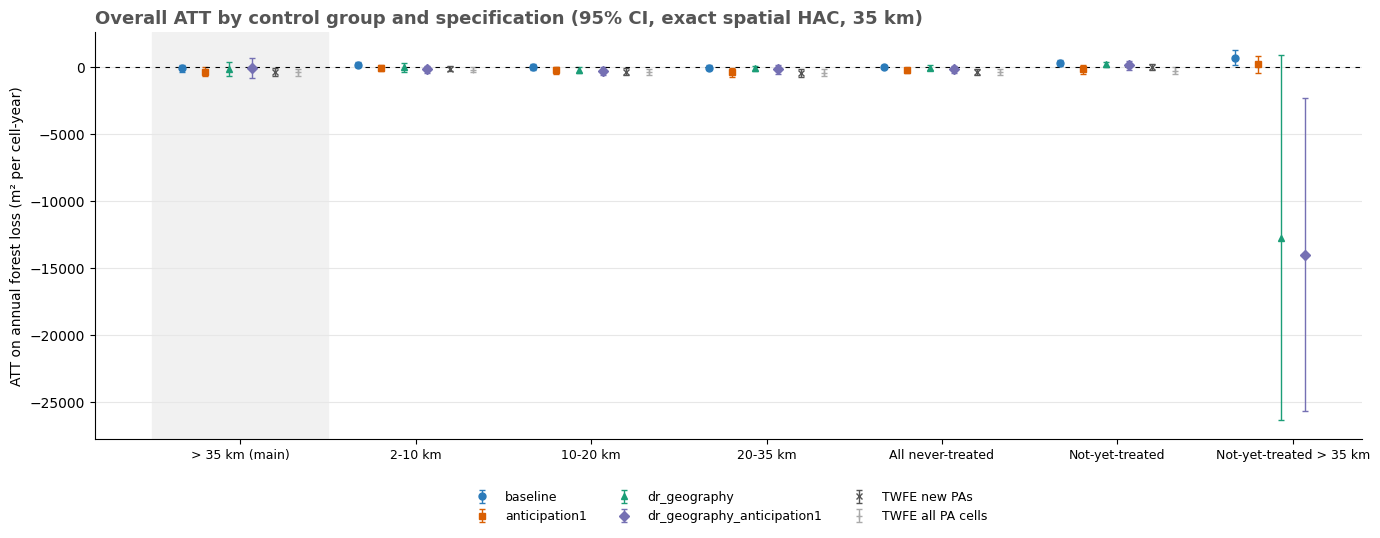

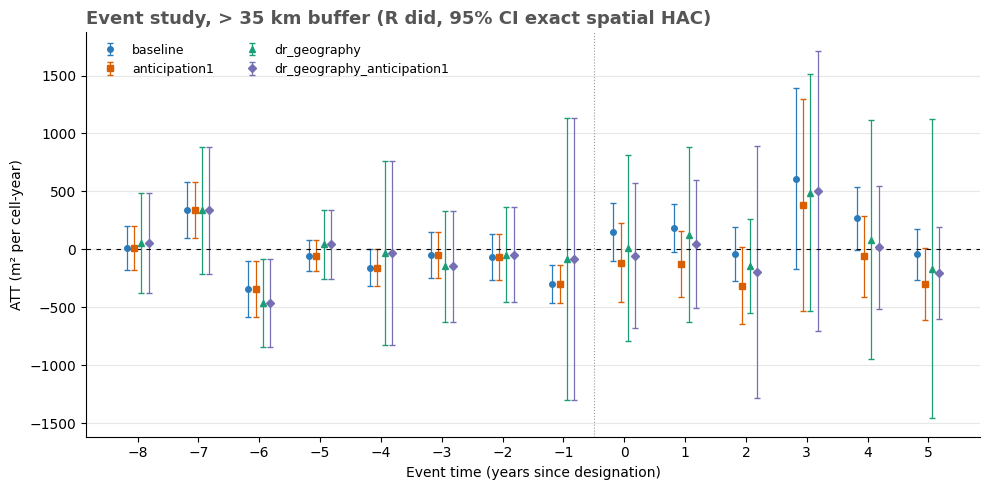

In [10]:
colors = {'baseline': '#2b7bba', 'anticipation1': '#d95f02', 'dr_geography': '#1b9e77', 'dr_geography_anticipation1': '#7570b3',
          'TWFE new PAs': '#555555', 'TWFE all PA cells': '#aaaaaa'}
markers = {'baseline': 'o', 'anticipation1': 's', 'dr_geography': '^', 'dr_geography_anticipation1': 'D', 'TWFE new PAs': 'x', 'TWFE all PA cells': '+'}
fig, ax = plt.subplots(figsize=(14, 5.5))
xpos = np.arange(len(order_cols))
off = np.linspace(-0.33, 0.33, len(order_rows))
for k, s in enumerate(order_rows):
    d = both[both['spec'] == s].set_index('control_label').reindex(order_cols)
    ax.errorbar(xpos + off[k], d['att'], yerr=1.96 * d['se_hac'], fmt=markers[s], color=colors[s], ecolor=colors[s],
                capsize=2.5, markersize=5, linewidth=1, label=s)
ax.axhline(0, color='black', linewidth=0.8, linestyle=(0, (4, 5)))
ax.axvspan(-0.5, 0.5, color='#f1f1f1', zorder=0)
ax.set_xticks(xpos); ax.set_xticklabels(order_cols, fontsize=9)
ax.set_ylabel('ATT on annual forest loss (m² per cell-year)')
ax.set_title('Overall ATT by control group and specification (95% CI, exact spatial HAC, 35 km)', loc='left', color='#555555', fontsize=13, weight='bold')
ax.grid(True, axis='y', color='#e7e7e7'); ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.legend(frameon=False, ncol=3, fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.1))
fig.tight_layout()
fig.savefig(FIG_DIR / f'12_overall_att_by_control_group_{RUN_TAG}.png', dpi=220, bbox_inches='tight'); plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
for k, s in enumerate([sp['spec'] for sp in SPECS]):
    d = cs_events[(cs_events['control_group'] == MAIN_GROUP) & (cs_events['spec'] == s)].sort_values('event_time')
    ax.errorbar(d['event_time'] + (k - 1.5) * 0.12, d['att'], yerr=1.96 * d['se_hac'], fmt=markers[s], color=colors[s], ecolor=colors[s],
                capsize=2, markersize=4, linewidth=0.9, label=s)
ax.axhline(0, color='black', linewidth=0.8, linestyle=(0, (4, 5)))
ax.axvline(-0.5, color='#999999', linewidth=0.8, linestyle=':')
ax.set_xticks(range(EVENT_WINDOW[0], EVENT_WINDOW[1] + 1))
ax.set_xlabel('Event time (years since designation)'); ax.set_ylabel('ATT (m² per cell-year)')
ax.set_title('Event study, > 35 km buffer (R did, 95% CI exact spatial HAC)', loc='left', color='#555555', fontsize=13, weight='bold')
ax.grid(True, axis='y', color='#e7e7e7'); ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.legend(frameon=False, fontsize=9, ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / f'12_event_study_buffer35_{RUN_TAG}.png', dpi=220, bbox_inches='tight'); plt.show()

In [11]:
shutil.rmtree(R_WORK_DIR, ignore_errors=True)
print('Removed temporary R files:', R_WORK_DIR)

Removed temporary R files: C:\Users\cpedr\OneDrive - Hertie School\PhD\Paper 2\paper2\data\intermediate\12_r_did_work


### Notes for interpretation

* **SEs.** The spatial-HAC SEs are expected to be several times the analytic ones: forest loss and its shocks are spatially correlated well beyond a single cell (see the semivariograms in notebook 10). They use every pair within 35 km and the covariance across (g,t) cells.
* **DR.** R's DR estimator (`DRDID`) fits an unregularised logit propensity score and a linear outcome model, and its influence function includes their estimation; any overlap problems show up in the R warnings table above. The in-house DR of notebook 08 (regularised and trimmed propensity score) is used only for the buffered not-yet-treated group and is expected to give smaller effects.
* **Control groups.** A near-border band that disagrees with the > 35 km buffer is the leakage / frontier-selection signature notebook 08 documented. The not-yet-treated groups compare new PAs with areas protected later: they address frontier selection but assume no anticipation of designation, and the unbuffered version includes future protected cells next to existing parks. Without never-treated cells, R `did` uses the last cohort (2025) as the comparison group in the not-yet-treated column, so that cohort is not estimated as treated there.